<a href="https://colab.research.google.com/github/claramanolache/DeepLearning/blob/main/%5BCS_12B%5D_Module_4_Practice_Activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Updated on Tuesday, October 27th, 2026 to fix an incorrectly-named variable.

## Module 4 Practice Activity

**You do not need to submit this Notebook.** It is for practice only.

To begin, select "Copy to Drive" at the top (or alternatively download the Notebook file to a local machine for use with Jupyter).

This instance of the Notebook belongs to you, and you are encouraged to make changes to it. Experimentation often leads to new insights and deeper understanding.

If you ever need to revert back to the original version, you can simply make a new copy by accessing it from Canvas again.

For brevity, descriptions are not provided for some of the setup steps below. See the **Module 1 Practice Activity** Notebook for explanations of these steps.

### Goals
- Create networks with recurrent layers
- Understand the additional logic required to pass data from recurrent to subsequent layers
- Window data to forecast with a time series

### Learn by Experimenting
Please do not simply click "Run all" at the top before reading, as much of the value of this document is to serve as an interactive exploration from one section to the next. In fact, it will help significantly with learning if you first try to understand what the code in a cell might be doing before you run it and get the answer.

Additionally, as you read through the Notebook, you are highly encouraged to change the values in cells to see how the output changes when the cells are re-run. In doing so, you will gain a better understanding of how the various operations behave.

### Notebook Troubleshooting
If you get an unexpected error, the fix is often to click "Run before" from the Runtime menu to run all cells prior to the currently selected cell. If the error persists and you are not sure how to continue, please post on our Canvas forum or send me a message directly with information about the problem.

## Import Modules

In [1]:
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils import data

In [2]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

### Data Loader Helper Function

Since we will be performing regression tasks, the target is stored as a `FloatTensor` rather than the `LongTensor` used previously for integer class labels.

In [3]:
def create_data_loader(X, y, batch_size=32, shuffle=True):
    return data.DataLoader(
        data.TensorDataset(
            torch.FloatTensor(X),
            torch.FloatTensor(y)
        ),
        batch_size=batch_size,
        shuffle=shuffle
    )

## Practicing with Synthetic Data

Before we look at real-world data, let's start with a simple synthetic "dataset" composed of points along a sine wave.

In [4]:
t = np.linspace(0, 100, 1000)
sine_wave = np.sin(t)
pd.Series(sine_wave, name="sine").describe()

,sine
count,1000.000000
mean,0.001121
std,0.708733
min,-1.000000
25%,-0.707179
50%,0.007684
75%,0.712352
max,1.000000


The goal when working with sequential data is often to predict the next value in the sequence, given previous values.

For each next-step target to predict, we can create a window of the past `window_size` time steps, which serve as the features for that target's sample. The window should be sufficiently large to detect patterns, but larger windows can also capture more noise and add significantly to training time.

As an example, if `window_size` is 10, then one sample could have as its features time steps 5 through 14, and its target to predict would be time step 15.

In [5]:
window_size = 50

Below, we create windowed features by taking `window_size` slices of the sine wave.

In a typical case (assuming no truncated or overlapping windows), a dataset of size `D` and window size of length `W` results in `D - W` samples to allow the first sample to occur after the first full window. As such, the target vector is sliced accordingly.

Given the simplicity of this data, we will ignore the need for a validation and test set here (but will use them in the next section).

In [6]:
X = np.zeros((len(sine_wave) - window_size, window_size))
for i in range(len(sine_wave) - window_size):
    X[i] = sine_wave[i:i + window_size]
X = torch.tensor(X).float().reshape(-1, window_size, 1)
y = torch.tensor(sine_wave[window_size:]).float().reshape(-1, 1)

X.shape, y.shape

(torch.Size([950, 50, 1]), torch.Size([950, 1]))

Next, we create the data loader as in previous activities. Even though `shuffle` is set to true, only the windows themselves will get shuffled with each other, not the time step order within each window.

In [7]:
loader = create_data_loader(X, y)

In [8]:
model = nn.Sequential(
    nn.RNN(
        input_size=1,
        hidden_size=32,
        num_layers=1,
        batch_first=True
    ),
    nn.Linear(32, 1)
)

Due to the presence of the hidden outputs from the recurrent layer, we must explicitly capture the layer's outputs and feed them into the feedforward (linear) output layer.

The function below indexes on the model, with an index of 0 referring to the first component, `nn.RNN`, and an index of 1 referring to the second component, `nn.Linear`. To call these components as functions is to pass in an input to that layer and have the layer's output returned.

Note that the recurrent layer at `model[0]` returns two values: the output of the layer and the recurrent "hidden" outputs to be fed back into itself. As we do not need to capture the hidden outputs, they are assigned to an underscore variable, which is a Python idiom to indicate that an assigned value is not needed.

In [9]:
def get_next_prediction(
    model: nn.Sequential, inputs: torch.Tensor
) -> torch.Tensor:
    outputs, _ = model[0](inputs)
    last_time_step = outputs[:, -1, :]
    return model[1](last_time_step)

### Set Hyperparameters

Here we use `MSELoss` as the cost function for this regression task.

In [10]:
n_epochs = 10
learning_rate = 0.01
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.MSELoss()

In addition to the different cost function, the training loop here differs from previous examples in how model predictions are captured.

Previously, we used:
```python
y_pred = model(X_batch)
```

For this recurrent network, we instead call the `get_next_prediction` function defined previously, which manages the flow of data from the recurrent layer to the output layer.

In [11]:
model.to(device)
model.train()
for epoch in range(n_epochs):
    total_loss = 0.0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        y_pred = get_next_prediction(model, X_batch)

        loss = criterion(y_pred, y_batch)
        total_loss += loss.item()
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

Normally we would use batches during evaluation too, but since there is no explicit test set and the dataset itself is small, we can get predictions across its entirety.

In [12]:
model.eval()
with torch.no_grad():
        X = X.to(device)
        y_pred = get_next_prediction(model, X).cpu().numpy()

Let's now compute the Root Mean Squared Error (RMSE) for these predictions. We can use a package like scikit-learn for this purpose, though it is also easy to compute with NumPy.

In [13]:
difference = y_pred - y.numpy()
rmse = np.sqrt(np.mean(difference ** 2))
rmse

np.float32(0.005954058)

Finally, let's also plot the original sine wave with the model's predictions.

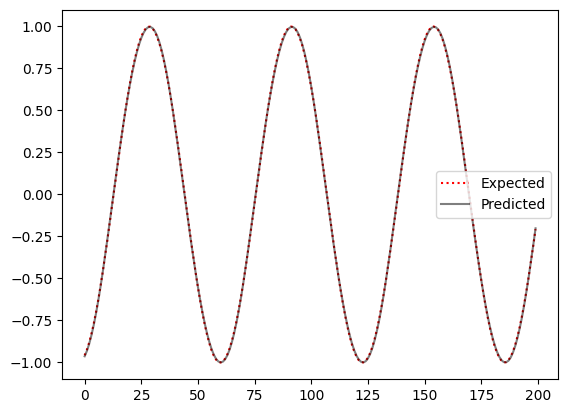

In [14]:
plt.plot(y.numpy()[:200], label="Expected", color="red", linestyle=":")
plt.plot(y_pred[:200], label="Predicted", color="black", alpha=0.5)
plt.legend()
plt.show()

The model does quite well! Of course, the data is very simple and we effectively evaluated the model on its training data.

Next, let's pivot to using a real-world dataset.

## Predicting Real Climate Data

In this section, we use climate data collected in Jena, Germany. There are several features (defined below), but we will mainly be concerned with temperature ("T (degC)").

### Jena Climate Dataset Field Definitions

| Field | Description |
| :--- | :--- |
| **Date Time** | Time of observation |
| **p (mbar)** | Atmospheric pressure (millibar) |
| **T (degC)** | Temperature (Celsius) |
| **Tpot (K)** | Potential temperature (Kelvin) |
| **Tdew (degC)** | Dew point temperature (Celsius) |
| **rh (%)** | Relative humidity (%) |
| **VPmax (mbar)** | Saturation vapor pressure (millibar) |
| **VPact (mbar)** | Actual vapor pressure (millibar) |
| **VPdef (mbar)** | Vapor pressure deficit (millibar) |
| **sh (g/kg)** | Specific humidity (g/kg) |
| **H2OC (mmol/mol)** | Water vapor concentration (mmol/mol) |
| **rho (g/m**3)** | Air density (g/m**3) |
| **wv (m/s)** | Wind velocity (m/s) |
| **max. wv (m/s)** | Maximum wind velocity (m/s) |
| **wd (deg)** | Wind direction (degrees) |

### Download the Dataset

In [15]:
url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
df = pd.read_csv(url)
df.shape

(420551, 15)

Convert the "Date Time" column into the Pandas `datetime` data type, and set it as the index of the DataFrame.

In [16]:
df["Date Time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S")
df.set_index("Date Time", inplace=True)

### Inspect the Data

Let's inspect the start and end times of the data.

In [17]:
df.index.min(), df.index.max()

(Timestamp('2009-01-01 00:10:00'), Timestamp('2017-01-01 00:00:00'))

The data is provided in 10-minute intervals, which is perhaps too granular for a simple temperature prediction.

Pandas has a very elegant method for aggregating time series into larger intervals. Below, we combine samples into 3-hour intervals, taking each feature's average values across the samples in each 3-hour interval.

In [18]:
df = df.resample("3h").mean()
df.shape

(23377, 14)

It turns out that this aggregation introduced some null values (several 10-minute intervals in the original data are missing, resulting in empty 3-hour intervals). We can simply drop these rows.

In [19]:
df = df.dropna()
df.shape

(23348, 14)

From the difference in row count before and after dropping null values, we can see that very few rows were lost.

Now let's take a high-level look at the dataset before we prepare the data further.

In [20]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
p (mbar),23348.0,989.214731,8.351333,943.201667,984.201944,989.573611,994.718472,1015.112778
T (degC),23348.0,9.442007,8.382105,-22.386667,3.376944,9.412222,15.486944,36.734444
Tpot (K),23348.0,283.484420,8.462583,251.268889,277.445417,283.462778,289.536806,310.678889
Tdew (degC),23348.0,4.953103,6.717141,-24.376667,0.244167,5.215833,10.067361,22.070556
rh (%),23348.0,76.028810,16.079085,16.846667,65.733194,79.130556,88.944444,100.000000
VPmax (mbar),23348.0,13.568358,7.678022,1.004444,7.793889,11.832778,17.650833,61.916111
VPact (mbar),23348.0,9.532171,4.172178,0.838889,6.219861,8.864444,12.359722,26.600556
VPdef (mbar),23348.0,4.036104,4.798698,0.000000,0.914444,2.239444,5.289028,44.143889
sh (g/kg),23348.0,6.021398,2.648511,0.526667,3.923333,5.595833,7.808889,16.990000
H2OC (mmol/mol),23348.0,9.638612,4.223278,0.846111,6.293333,8.965556,12.495556,27.035000


We can plot the temperature data to see its **seasonality** - patterns that repeat, in this case, every year.

In plotting the entire dataset, we are learning something about what will become test data, which could bias our decisions about model architecture. In a real-world scenario, you may wish to split the data before inspecting it at all.

<Axes: xlabel='Date Time'>

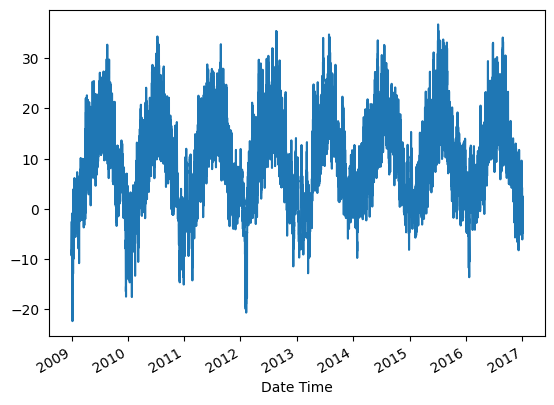

In [21]:
df["T (degC)"].plot()

### Prepare the Data

Due to the annual seasonality of the data, it makes sense for the splits to occur along annual boundaries. We will reserve 2 years for validation and 1 year for testing. (Recall that the data ranges from the start of 2009 to the end of 2016.)

In [22]:
val_start = df.index.get_loc("2014-01-01 00:00:00")
test_start = df.index.get_loc("2016-01-01 00:00:00")

In [23]:
df_train = df[:val_start]
df_val = df[val_start:test_start]
df_test = df[test_start:]

df_train.shape, df_val.shape, df_test.shape

((14608, 14), (5835, 14), (2905, 14))

Now we normalize the data, using the mean and standard deviation of the training data.

Importantly, always normalize using the mean and standard deviation from the training data. If you compute the validation and test set statistics, you would be using information that was not meant to be available at the time the model was created.

In [24]:
train_mean = df_train.mean()
train_std = df_train.std()

df_train_norm = (df_train - train_mean) / train_std
df_val_norm = (df_val - train_mean) / train_std
df_test_norm = (df_test - train_mean) / train_std

Let's visualize the distribution of each feature post-normalization.

In [25]:
df_train_norm.describe().T

,count,mean,std,min,25%,50%,75%,max
p (mbar),14608.0,5.254553e-13,1.0,-5.421365,-0.602843,0.062646,0.663022,2.814588
T (degC),14608.0,1.634326e-15,1.0,-3.594806,-0.715094,0.013173,0.727318,3.050640
Tpot (K),14608.0,2.287278e-13,1.0,-3.611914,-0.697526,0.020958,0.720104,3.030502
Tdew (degC),14608.0,-2.116841e-15,1.0,-4.082927,-0.665798,0.066011,0.762167,2.500833
rh (%),14608.0,-1.346179e-14,1.0,-3.689835,-0.632553,0.197462,0.800944,1.481596
VPmax (mbar),14608.0,-4.739546e-15,1.0,-1.601637,-0.760009,-0.221019,0.546229,5.834962
VPact (mbar),14608.0,-8.607451e-15,1.0,-2.013813,-0.782940,-0.143496,0.685913,4.140854
VPdef (mbar),14608.0,-5.720141e-16,1.0,-0.838665,-0.657124,-0.384812,0.265293,8.036483
sh (g/kg),14608.0,-4.521636e-15,1.0,-2.006538,-0.781142,-0.145463,0.684105,4.191609
H2OC (mmol/mol),14608.0,-2.023451e-16,1.0,-2.013172,-0.781188,-0.144150,0.685292,4.168384


Now let's split each set by features and targets.

Here we set the temperature as the target - though you are welcome to try predicting a different target!

In [26]:
X_train = df_train_norm.drop("T (degC)", axis=1)
y_train = df_train_norm["T (degC)"]

X_val = df_val_norm.drop("T (degC)", axis=1)
y_val = df_val_norm["T (degC)"]

X_test = df_test_norm.drop("T (degC)", axis=1)
y_test = df_test_norm["T (degC)"]

X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape

((14608, 13), (14608,), (5835, 13), (5835,), (2905, 13), (2905,))

#### Window the Features

As with the sine wave example, we want each value in the target vector to correspond to a range of features from the past `window_size` time steps.

Here, I chose a starting window size of 40; after the 3-hour interval aggregation, there are 8 samples per day, so this would represent 5 days.

Experiment with different window sizes to see how it impacts performance.

In [27]:
window_size = 40

In [28]:
n_features = X_train.shape[1]

The code here is very similar to that used in the sine wave example. I put it in a function so that it can be applied to each of the training, validation, and test sets.

In [29]:
def window_dataset(
    X, window_size: int, n_features: int
) -> torch.tensor:
    X_win = np.zeros((len(X) - window_size, window_size, n_features))
    for i in range(len(X) - window_size):
        X_win[i] = X[i:i + window_size]
    X_win = torch.tensor(X_win).float()
    return X_win.reshape(-1, window_size, n_features)

In [30]:
X_train_win = window_dataset(X_train.to_numpy(), window_size, n_features)
X_val_win = window_dataset(X_val.to_numpy(), window_size, n_features)
X_test_win = window_dataset(X_test.to_numpy(), window_size, n_features)

X_train_win.shape, X_val_win.shape, X_test_win.shape

(torch.Size([14568, 40, 13]),
 torch.Size([5795, 40, 13]),
 torch.Size([2865, 40, 13]))

As with the sine wave, we need to slice out the first `window_size` values of the target vector so that the feature matrices and target vectors have the same number of samples.

In [31]:
y_train_win = torch.tensor(
    y_train.iloc[window_size:].values
).float().reshape(-1, 1)

y_val_win = torch.tensor(
    y_val.iloc[window_size:].values
).float().reshape(-1, 1)

y_test_win = torch.tensor(
    y_test.iloc[window_size:].values
).float().reshape(-1, 1)

y_train_win.shape, y_val_win.shape, y_test_win.shape

(torch.Size([14568, 1]), torch.Size([5795, 1]), torch.Size([2865, 1]))

With the windowing complete, we can now create the data loaders to batch the samples during training and evaluation.

In [32]:
train_loader = create_data_loader(X_train_win, y_train_win)
val_loader = create_data_loader(X_val_win, y_val_win)
test_loader = create_data_loader(X_test_win, y_test_win, shuffle=False)

len(train_loader), len(val_loader), len(test_loader)

(456, 182, 90)

### Define the Model

Here we use a Long Short-Term Memory (LSTM) model, rather than a simple RNN (as before). While recurrent inputs are easily forgotten in standard RNNs, an LSTM recurrent layer learns to selectively remember important information.

In [33]:
model = nn.Sequential(
    nn.LSTM(
        input_size=X_train.shape[1],
        hidden_size=64,
        num_layers=2,
        batch_first=True
    ),
    nn.Linear(64, 1)
)

### Set Hyperparameters

In [34]:
n_epochs = 10
learning_rate = 0.001
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.MSELoss()
patience = 5

### Train the Model

This training loop uses Early Stopping, introduced in the previous module. In addition, it also uses the `get_next_prediction` function defined above and as used in the sine wave example.

In [35]:
avg_costs = []
best_cost = float("inf")
best_params = None

model.to(device)
for epoch in range(n_epochs):
    model.train()
    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        y_pred = get_next_prediction(model, X_batch)

        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            y_pred = get_next_prediction(model, X_batch)

            loss = criterion(y_pred, y_batch)
            val_loss += loss.item()
    avg_costs.append(val_loss / len(val_loader))

    print(f"Epoch {epoch:3d} | Validation Cost: {avg_costs[-1]:.4f} | Best: {best_cost:.4f}")
    if avg_costs[-1] < best_cost:
        best_cost = avg_costs[-1]
        best_params = copy.deepcopy(model.state_dict())
    elif len(avg_costs) > patience and min(avg_costs[-patience:]) > best_cost:
        print("Early Stopping Triggered")
        break

Epoch   0 | Validation Cost: 0.0284 | Best: inf
Epoch   1 | Validation Cost: 0.0201 | Best: 0.0284
Epoch   2 | Validation Cost: 0.0217 | Best: 0.0201
Epoch   3 | Validation Cost: 0.0198 | Best: 0.0201
Epoch   4 | Validation Cost: 0.0180 | Best: 0.0198
Epoch   5 | Validation Cost: 0.0199 | Best: 0.0180
Epoch   6 | Validation Cost: 0.0186 | Best: 0.0180
Epoch   7 | Validation Cost: 0.0177 | Best: 0.0180
Epoch   8 | Validation Cost: 0.0184 | Best: 0.0177
Epoch   9 | Validation Cost: 0.0182 | Best: 0.0177


### Evaluate the Model

As this task is regression, we do not need to get the predicted label with `torch.argmax`, and instead can add up the total cost to get its average after iterating over all batches.

In [36]:
y_pred_list = []
model.load_state_dict(best_params)
model.eval()
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        y_pred = get_next_prediction(model, X_batch)
        y_pred_list.append(y_pred.cpu().numpy())

        loss = criterion(y_pred, y_batch)

The evaluation loop gathered a list of arrays, which we need to concatenate to be the same dimension as the target array.

In [37]:
y_pred = np.concatenate(y_pred_list, axis=0)
y_pred.shape

(2865, 1)

Now we can compute the RMSE. However, recall that we normalized the data (including the target), so if we want the RMSE to be in degrees Celsius, we need to first reverse the normalization.

In [38]:
temp_mean = train_mean["T (degC)"]
temp_std = train_std["T (degC)"]

y_pred_temp = (y_pred * temp_std) + temp_mean
y_test_temp = (y_test_win.numpy() * temp_std) + temp_mean

difference = y_pred_temp - y_test_temp
rmse = np.sqrt(np.mean(difference ** 2))
rmse

np.float64(1.0481977537901146)

Finally, let's plot the expected versus predicted values.

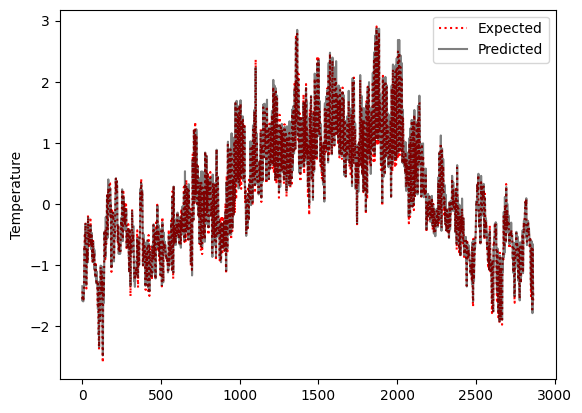

In [39]:
plt.plot(y_test_win.numpy(), label="Expected", color="red", linestyle=":")
plt.plot(y_pred, label="Predicted", color="black", alpha=0.5)
plt.ylabel("Temperature")
plt.legend()
plt.show()

---

## Next Steps

The Jena Climate example used all features to predict the temperature at the next interval, but what if you used fewer features - or just the temperature itself? See if removing certain features reduces noise and results in better predictions.

In fact, one of the features is actually composed of circular data, and requires more preprocessing to be normalized properly. Another feature has some extreme values that may represent placeholders for missing sensor data. Can you identify and fix these issues? Does it result in better performance?

The project for this module will have you select a sequential dataset, such as a time series. Please post on this module's Q&A forum if you have any questions about the suitability of a dataset.

Upcoming readings on Canvas will provide some additional information about recurrent networks.